# EA3 — Comparación de datos climáticos: Medellín y Ciudad de México

**Autor:** Santiago Valencia Duque
**Curso:** Analítica de Datos — IU Digital
**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y Ciudad de México durante el mismo periodo?

## 1. Fuentes y datos utilizados

| | Medellín (Colombia) | Ciudad de México (México) |
|---|---|---|
| **Fuente** | Open-Meteo Historical Weather API | Open-Meteo Historical Weather API |
| **Enlace** | https://open-meteo.com/en/docs/historical-weather-api | https://open-meteo.com/en/docs/historical-weather-api |
| **Modelo** | Reanálisis ERA5 (ECMWF), malla de unos 9–25 km | Igual |
| **Coordenadas pedidas** | 6.2518 N, -75.5636 O | 19.4326 N, -99.1332 O |
| **Periodo** | 2025-01-01 a 2025-12-31 | 2025-01-01 a 2025-12-31 |
| **Frecuencia** | Diaria | Diaria |
| **Zona horaria** | `timezone=auto` (America/Bogota) | `timezone=auto` (America/Mexico_City) |

**Columnas utilizadas** (idénticas en ambas tablas):

| Columna original | Variable | Unidad |
|---|---|---|
| `temperature_2m_max (°C)` | Temperatura máxima diaria a 2 m | °C |
| `temperature_2m_min (°C)` | Temperatura mínima diaria a 2 m | °C |
| `temperature_2m_mean (°C)` | Temperatura media diaria a 2 m | °C |
| `precipitation_sum (mm)` | Precipitación diaria acumulada | mm |
| `wind_speed_10m_max (km/h)` | Velocidad máxima del viento a 10 m | km/h |

**Variables comparables:** temperatura máxima diaria (°C) y precipitación diaria (mm).

**Conversión de unidades:** las dos tablas se pidieron a la misma API con los mismos parámetros, así que ya vienen en °C, mm y km/h. No hizo falta convertir nada.

**Advertencia sobre la fuente:** Open-Meteo entrega datos de reanálisis, es decir, un modelo que asimila observaciones. No son lecturas de una estación física. El valor corresponde a una celda de malla, no a un punto exacto de la ciudad. Esto se retoma en las limitaciones.

## 2. Plantea la comparación

**Periodo común:** del 1 de enero al 31 de diciembre de 2025 (365 días, frecuencia diaria) en las dos ciudades.

**Variables que se comparan:** temperatura máxima diaria (°C) y precipitación diaria (mm). Como tercera variable uso la amplitud térmica diaria (Tmax − Tmin, en °C).

**Expectativa antes de calcular:**

1. Medellín queda a unos 1 500 m de altitud y Ciudad de México a unos 2 240 m, pero Medellín está mucho más cerca del ecuador. Espero que Medellín tenga una temperatura máxima casi constante durante el año, y que Ciudad de México varíe más.
2. Espero que Medellín tenga lluvia repartida en casi todo el año, con dos temporadas más húmedas. Espero que Ciudad de México tenga una temporada de lluvias concentrada entre mayo y octubre, y meses casi secos entre noviembre y abril.
3. Espero que Ciudad de México acumule menos precipitación anual que Medellín.

## 3. Carga y revisión de los datos

### 3.1 Importar librerías y descargar los archivos

Los CSV están en la carpeta `datos/`. Si no existen, la celda siguiente los descarga desde Open-Meteo con los mismos parámetros que usé.

In [1]:
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATOS = Path("datos")
DATOS.mkdir(exist_ok=True)

INICIO, FIN = "2025-01-01", "2025-12-31"
VARIABLES = ("temperature_2m_max,temperature_2m_min,temperature_2m_mean,"
             "precipitation_sum,wind_speed_10m_max")

CIUDADES = {
    "Medellín":         {"archivo": "medellin.csv",         "lat": 6.2518,  "lon": -75.5636},
    "Ciudad de México": {"archivo": "ciudad_de_mexico.csv", "lat": 19.4326, "lon": -99.1332},
}

for nombre, c in CIUDADES.items():
    ruta = DATOS / c["archivo"]
    if not ruta.exists():
        url = ("https://archive-api.open-meteo.com/v1/archive"
               f"?latitude={c['lat']}&longitude={c['lon']}"
               f"&start_date={INICIO}&end_date={FIN}"
               f"&daily={VARIABLES}&timezone=auto&format=csv")
        urllib.request.urlretrieve(url, ruta)
        print(f"Descargado: {ruta}")
    else:
        print(f"Ya existe: {ruta}")

Ya existe: datos\medellin.csv
Ya existe: datos\ciudad_de_mexico.csv


### 3.2 Leer las tablas

Cada CSV de Open-Meteo trae dos filas de metadatos (coordenadas, elevación, zona horaria), una línea en blanco y después la tabla diaria. Por eso leo los metadatos y la tabla por separado, con `skiprows=3` para la tabla.

In [2]:
meta, tablas = {}, {}
for nombre, c in CIUDADES.items():
    ruta = DATOS / c["archivo"]
    meta[nombre] = pd.read_csv(ruta, nrows=1)            # fila de metadatos
    tablas[nombre] = pd.read_csv(ruta, skiprows=3)       # tabla diaria

print("Metadatos devueltos por la API (celda de malla realmente usada):")
display(pd.concat(meta, names=["ciudad"]).droplevel(1))

Metadatos devueltos por la API (celda de malla realmente usada):


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
ciudad,,,,,,
Medellín,6.221441,-75.55185,1493.0,-18000,America/Bogota,GMT-5
Ciudad de México,19.437609,-99.10715,2230.0,-21600,America/Mexico_City,GMT-6


In [3]:
for nombre, df in tablas.items():
    print("=" * 70)
    print(nombre)
    print("Columnas:", list(df.columns))
    print("Dimensiones (filas, columnas):", df.shape)
    display(df.head(4))

Medellín
Columnas: ['time', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'temperature_2m_mean (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)']
Dimensiones (filas, columnas): (365, 6)


,time,temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C),precipitation_sum (mm),wind_speed_10m_max (km/h)
0,2025-01-01,26.0,15.4,19.2,13.5,8.7
1,2025-01-02,26.3,15.9,19.5,10.0,4.3
2,2025-01-03,23.4,15.5,18.9,8.8,5.7
3,2025-01-04,25.8,15.4,19.4,19.4,5.4


Ciudad de México
Columnas: ['time', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'temperature_2m_mean (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)']
Dimensiones (filas, columnas): (365, 6)


,time,temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C),precipitation_sum (mm),wind_speed_10m_max (km/h)
0,2025-01-01,23.3,8.2,15.5,0.0,13.2
1,2025-01-02,22.2,8.5,14.6,0.0,14.8
2,2025-01-03,21.2,9.0,14.2,0.1,13.9
3,2025-01-04,20.7,10.4,15.0,0.2,11.1


### 3.3 Tipos de datos y renombrado

La columna `time` llega como texto. La convierto a `datetime64` y las mediciones a `float` con `pd.to_numeric(errors="coerce")`. Así cualquier valor no numérico queda como `NaN`, que es un faltante real, y no se convierte en cero. Renombro las columnas con nombres cortos y dejo las unidades en un diccionario.

In [4]:
RENOMBRAR = {
    "time": "fecha",
    "temperature_2m_max (°C)": "tmax",
    "temperature_2m_min (°C)": "tmin",
    "temperature_2m_mean (°C)": "tmedia",
    "precipitation_sum (mm)": "precip",
    "wind_speed_10m_max (km/h)": "viento",
}
UNIDADES = {"tmax": "°C", "tmin": "°C", "tmedia": "°C", "precip": "mm", "viento": "km/h"}

for nombre, df in tablas.items():
    df = df.rename(columns=RENOMBRAR)
    df["fecha"] = pd.to_datetime(df["fecha"], format="%Y-%m-%d")
    for col in UNIDADES:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    tablas[nombre] = df

for nombre, df in tablas.items():
    print(nombre)
    print(df.dtypes.to_string(), "\n")

Medellín
fecha     datetime64[ns]
tmax             float64
tmin             float64
tmedia           float64
precip           float64
viento           float64 

Ciudad de México
fecha     datetime64[ns]
tmax             float64
tmin             float64
tmedia           float64
precip           float64
viento           float64 



### 3.4 Fechas inicial y final, faltantes y duplicados

In [5]:
fechas_esperadas = pd.date_range(INICIO, FIN, freq="D")
resumen = []
for nombre, df in tablas.items():
    resumen.append({
        "ciudad": nombre,
        "filas": len(df),
        "fecha_inicial": df["fecha"].min().date(),
        "fecha_final": df["fecha"].max().date(),
        "fechas_duplicadas": int(df["fecha"].duplicated().sum()),
        "fechas_faltantes_del_calendario": int(len(fechas_esperadas.difference(df["fecha"]))),
        "frecuencia_diaria": bool((df["fecha"].diff().dropna() == pd.Timedelta(days=1)).all()),
    })
display(pd.DataFrame(resumen).set_index("ciudad"))

print("Valores faltantes por columna:")
display(pd.DataFrame({n: df.isna().sum() for n, df in tablas.items()}))

,filas,fecha_inicial,fecha_final,fechas_duplicadas,fechas_faltantes_del_calendario,frecuencia_diaria
ciudad,,,,,,
Medellín,365,2025-01-01,2025-12-31,0,0,True
Ciudad de México,365,2025-01-01,2025-12-31,0,0,True


Valores faltantes por columna:


,Medellín,Ciudad de México
fecha,0,0
tmax,0,0
tmin,0,0
tmedia,0,0
precip,0,0
viento,0,0


**Lectura:** las dos tablas tienen 365 filas, del 2025-01-01 al 2025-12-31, sin fechas duplicadas, sin huecos en el calendario y sin valores faltantes. Como no hay `NaN`, no reemplazo ni elimino ningún valor.

**Sobre los ceros en precipitación:** la fuente reporta `precipitation_sum` como la suma diaria del modelo, y `0.00` significa que el modelo no calculó lluvia ese día. Lo interpreto como día sin lluvia porque no hay `NaN`. Si hubiera faltantes, no los habría convertido en cero.

### 3.5 Fechas válidas en ambas tablas

Para comparar día a día uso solo las fechas que tienen datos válidos de temperatura máxima y precipitación en las dos ciudades. Uno las tablas por fecha con `merge`.

In [6]:
med = tablas["Medellín"]
mex = tablas["Ciudad de México"]

COLS_CLAVE = ["tmax", "precip"]
med_ok = med.dropna(subset=COLS_CLAVE)
mex_ok = mex.dropna(subset=COLS_CLAVE)

comun = med_ok.merge(mex_ok, on="fecha", suffixes=("_med", "_mex"), validate="one_to_one")

print(f"Fechas válidas en Medellín: {len(med_ok)}")
print(f"Fechas válidas en Ciudad de México: {len(mex_ok)}")
print(f"Fechas válidas en AMBAS (observaciones disponibles para comparar): {len(comun)}")
print(f"Periodo común: {comun['fecha'].min().date()} → {comun['fecha'].max().date()}")

Fechas válidas en Medellín: 365
Fechas válidas en Ciudad de México: 365
Fechas válidas en AMBAS (observaciones disponibles para comparar): 365
Periodo común: 2025-01-01 → 2025-12-31


Quedaron **365 observaciones diarias comparables**, una por cada día de 2025. No se descartó ninguna fecha.

## 4. Análisis con NumPy

### 4.1 Construir los arrays

Paso las columnas de la tabla unida a arrays de NumPy. Apilo las dos ciudades en arrays 2D de forma `(2, 365)`: la fila 0 es Medellín y la fila 1 es Ciudad de México.

In [7]:
CIUDAD_NOMBRES = ["Medellín", "Ciudad de México"]

fechas = comun["fecha"].to_numpy()                    # datetime64[ns], forma (365,)

tmax   = np.vstack([comun["tmax_med"].to_numpy(),   comun["tmax_mex"].to_numpy()])    # °C
tmin   = np.vstack([comun["tmin_med"].to_numpy(),   comun["tmin_mex"].to_numpy()])    # °C
precip = np.vstack([comun["precip_med"].to_numpy(), comun["precip_mex"].to_numpy()])  # mm

print("fechas :", fechas.shape, fechas.dtype)
print("tmax   :", tmax.shape,   tmax.dtype)
print("tmin   :", tmin.shape,   tmin.dtype)
print("precip :", precip.shape, precip.dtype)
print("¿hay NaN en los arrays?", np.isnan(tmax).any() or np.isnan(tmin).any() or np.isnan(precip).any())

fechas : (365,) datetime64[ns]
tmax   : (2, 365) float64
tmin   : (2, 365) float64
precip : (2, 365) float64
¿hay NaN en los arrays? False


### 4.2 Índices y cortes: inspeccionar un periodo breve

Tomo la primera semana de junio de 2025. Busco la posición del 1 de junio con `np.searchsorted` y corto 7 días con `slice`. Aplico el mismo corte a las dos ciudades.

In [8]:
i0 = np.searchsorted(fechas, np.datetime64("2025-06-01"))
corte = slice(i0, i0 + 7)

print("Días del corte:", fechas[corte].astype("datetime64[D]"))
print()
for i, nombre in enumerate(CIUDAD_NOMBRES):
    print(nombre)
    print("  Tmax (°C)      :", tmax[i, corte])
    print("  Precip. (mm)   :", precip[i, corte])
print()
print("Primer día del año (índice 0)  → Tmax Med / CDMX:", tmax[:, 0])
print("Último día del año (índice -1) → Tmax Med / CDMX:", tmax[:, -1])

Días del corte: ['2025-06-01' '2025-06-02' '2025-06-03' '2025-06-04' '2025-06-05'
 '2025-06-06' '2025-06-07']

Medellín
  Tmax (°C)      : [27.1 27.7 28.  28.1 27.2 27.7 28.5]
  Precip. (mm)   : [ 6.4  0.5  2.6  2.1  9.2 13.4  0. ]
Ciudad de México
  Tmax (°C)      : [22.1 23.2 23.8 24.9 25.7 26.4 26.5]
  Precip. (mm)   : [ 9.3 20.9  7.4  0.4  0.1  0.5  0.2]

Primer día del año (índice 0)  → Tmax Med / CDMX: [26.  23.3]
Último día del año (índice -1) → Tmax Med / CDMX: [27.7 20.9]


Este corte permite revisar los valores concretos de cada ciudad un mismo día. Es solo una semana, así que no sirve para generalizar sobre el año.

### 4.3 Máscaras booleanas

Defino dos umbrales y los aplico **igual a las dos ciudades**:

- **Día lluvioso:** precipitación diaria **≥ 1.0 mm**. Uso este umbral y no `> 0` para no contar lloviznas mínimas del modelo.
- **Día cálido:** temperatura máxima diaria **≥ 25 °C**.

In [9]:
UMBRAL_LLUVIA_MM = 1.0
UMBRAL_TEMP_C = 25.0

dia_lluvioso = precip >= UMBRAL_LLUVIA_MM      # (2, 365) bool
dia_calido   = tmax   >= UMBRAL_TEMP_C         # (2, 365) bool
lluvioso_y_calido = dia_lluvioso & dia_calido
sin_lluvia_exacta = precip == 0                # días con 0.00 mm

print(f"{'':26s}{'Medellín':>12s}{'CDMX':>12s}")
print(f"{'Días lluviosos (≥1 mm)':26s}{dia_lluvioso[0].sum():>12d}{dia_lluvioso[1].sum():>12d}")
print(f"{'Días cálidos (≥25 °C)':26s}{dia_calido[0].sum():>12d}{dia_calido[1].sum():>12d}")
print(f"{'Lluviosos y cálidos':26s}{lluvioso_y_calido[0].sum():>12d}{lluvioso_y_calido[1].sum():>12d}")
print(f"{'Días con 0.00 mm':26s}{sin_lluvia_exacta[0].sum():>12d}{sin_lluvia_exacta[1].sum():>12d}")

                              Medellín        CDMX
Días lluviosos (≥1 mm)             267         151
Días cálidos (≥25 °C)              332         119
Lluviosos y cálidos                234          12
Días con 0.00 mm                    21         143


In [10]:
# Uso de las máscaras para seleccionar valores (por ciudad)
for i, nombre in enumerate(CIUDAD_NOMBRES):
    tmax_lluvia = tmax[i][dia_lluvioso[i]].mean()
    tmax_seco   = tmax[i][~dia_lluvioso[i]].mean()
    print(f"{nombre:18s} Tmax media en días lluviosos: {tmax_lluvia:5.2f} °C | "
          f"en días no lluviosos: {tmax_seco:5.2f} °C | diferencia: {tmax_seco - tmax_lluvia:4.2f} °C")

Medellín           Tmax media en días lluviosos: 26.47 °C | en días no lluviosos: 27.86 °C | diferencia: 1.39 °C
Ciudad de México   Tmax media en días lluviosos: 22.65 °C | en días no lluviosos: 25.16 °C | diferencia: 2.51 °C


Medellín tiene muchos más días lluviosos que Ciudad de México y también muchos más días cálidos con el mismo umbral. En las dos ciudades, la temperatura máxima media es menor en los días lluviosos que en los no lluviosos. Esto es una asociación entre dos variables que observo en los datos. No muestra que la lluvia cause la baja de temperatura.

### 4.4 Medidas descriptivas por ciudad

In [11]:
estadisticas = pd.DataFrame({
    "Tmax media (°C)":           tmax.mean(axis=1),
    "Tmax mínima (°C)":          tmax.min(axis=1),
    "Tmax máxima (°C)":          tmax.max(axis=1),
    "Tmax desv. est. (°C)":      tmax.std(axis=1),
    "Precip. total (mm)":        precip.sum(axis=1),
    "Precip. diaria media (mm)": precip.mean(axis=1),
    "Precip. máx. diaria (mm)":  precip.max(axis=1),
    "Días lluviosos (≥1 mm)":    dia_lluvioso.sum(axis=1),
    "Días cálidos (≥25 °C)":     dia_calido.sum(axis=1),
}, index=CIUDAD_NOMBRES).round(2)

display(estadisticas.T)

,Medellín,Ciudad de México
Tmax media (°C),26.84,24.12
Tmax mínima (°C),21.60,14.50
Tmax máxima (°C),29.90,32.50
Tmax desv. est. (°C),1.39,3.09
Precip. total (mm),2193.90,1400.40
Precip. diaria media (mm),6.01,3.84
Precip. máx. diaria (mm),26.60,50.70
Días lluviosos (≥1 mm),267.00,151.00
Días cálidos (≥25 °C),332.00,119.00


### 4.5 Broadcasting

Uso broadcasting en tres operaciones:

1. **Anomalía térmica:** resto a cada array de forma `(2, 365)` su promedio de forma `(2, 1)`. NumPy expande la columna a lo largo de los 365 días.
2. **Amplitud térmica diaria:** `tmax - tmin`, elemento a elemento sobre arrays `(2, 365)`.
3. **Agregación mensual:** creo una máscara `(12, 365)` comparando `meses[None, :]` con `np.arange(1, 13)[:, None]`. Luego la multiplico por los datos con forma `(2, 1, 365)` para obtener resultados `(2, 12)`.

In [12]:
# 1) Anomalía: (2, 365) - (2, 1) -> (2, 365)
promedio_tmax = tmax.mean(axis=1, keepdims=True)
print("forma promedio_tmax:", promedio_tmax.shape)
anomalia_tmax = tmax - promedio_tmax
print("forma anomalia_tmax:", anomalia_tmax.shape)
print("Anomalía máxima (°C)  Med / CDMX:", anomalia_tmax.max(axis=1).round(2))
print("Anomalía mínima (°C)  Med / CDMX:", anomalia_tmax.min(axis=1).round(2))
print("Control: la anomalía promedia ~0 →", anomalia_tmax.mean(axis=1).round(10))

# 2) Amplitud térmica diaria
amplitud = tmax - tmin
print()
print("Amplitud térmica media (°C)  Med / CDMX:", amplitud.mean(axis=1).round(2))
print("Amplitud mínima / máxima Med :", amplitud[0].min().round(1), "/", amplitud[0].max().round(1))
print("Amplitud mínima / máxima CDMX:", amplitud[1].min().round(1), "/", amplitud[1].max().round(1))

# Días en que CDMX tuvo una Tmax más alta que Medellín
print()
print("Días con Tmax CDMX > Tmax Medellín:", int((tmax[1] > tmax[0]).sum()), "de", tmax.shape[1])

forma promedio_tmax: (2, 1)
forma anomalia_tmax: (2, 365)
Anomalía máxima (°C)  Med / CDMX: [3.06 8.38]
Anomalía mínima (°C)  Med / CDMX: [-5.24 -9.62]
Control: la anomalía promedia ~0 → [ 0. -0.]

Amplitud térmica media (°C)  Med / CDMX: [10.4  12.13]
Amplitud mínima / máxima Med : 5.0 / 13.6
Amplitud mínima / máxima CDMX: 3.8 / 18.9

Días con Tmax CDMX > Tmax Medellín: 82 de 365


In [13]:
# 3) Agregación mensual con broadcasting
meses = fechas.astype("datetime64[M]").astype(int) % 12 + 1          # 1..12, forma (365,)
mask_mes = meses[None, :] == np.arange(1, 13)[:, None]                # (12, 365)
dias_por_mes = mask_mes.sum(axis=1)                                   # (12,)

# (1,12,365) * (2,1,365) -> (2,12,365) -> suma sobre días -> (2,12)
tmax_mensual   = (mask_mes[None] * tmax[:, None, :]).sum(axis=2) / dias_por_mes
precip_mensual = (mask_mes[None] * precip[:, None, :]).sum(axis=2)
lluviosos_mes  = (mask_mes[None] * dia_lluvioso[:, None, :]).sum(axis=2)

print("forma mask_mes:", mask_mes.shape, "| tmax_mensual:", tmax_mensual.shape)
print("Días por mes:", dias_por_mes, "(suma =", dias_por_mes.sum(), ")")

NOMBRES_MES = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
tabla_mensual = pd.concat({
    "Tmax media (°C) Med":  pd.Series(tmax_mensual[0].round(1), index=NOMBRES_MES),
    "Tmax media (°C) CDMX": pd.Series(tmax_mensual[1].round(1), index=NOMBRES_MES),
    "Precip. (mm) Med":     pd.Series(precip_mensual[0].round(1), index=NOMBRES_MES),
    "Precip. (mm) CDMX":    pd.Series(precip_mensual[1].round(1), index=NOMBRES_MES),
    "Días lluviosos Med":   pd.Series(lluviosos_mes[0], index=NOMBRES_MES),
    "Días lluviosos CDMX":  pd.Series(lluviosos_mes[1], index=NOMBRES_MES),
}, axis=1)
display(tabla_mensual.T)

# Control: la suma mensual debe igualar el total anual
print("Control precipitación (suma mensual vs total):", precip_mensual.sum(axis=1).round(2), precip.sum(axis=1).round(2))
print("Precip. CDMX nov–abr:", precip_mensual[1][[10, 11, 0, 1, 2, 3]].sum().round(1),
      "mm | may–oct:", precip_mensual[1][4:10].sum().round(1), "mm")

forma mask_mes: (12, 365) | tmax_mensual: (2, 12)
Días por mes: [31 28 31 30 31 30 31 31 30 31 30 31] (suma = 365 )


,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Tmax media (°C) Med,27.3,25.7,26.8,26.9,26.7,26.9,28.2,27.1,27.3,26.2,26.5,26.4
Tmax media (°C) CDMX,22.7,23.8,27.7,28.6,27.4,22.6,22.9,23.0,23.0,23.3,23.3,21.2
Precip. (mm) Med,115.8,212.1,185.3,316.7,222.7,214.3,62.9,144.8,202.6,223.1,187.5,106.1
Precip. (mm) CDMX,10.0,15.9,7.5,2.0,136.1,331.9,220.1,240.4,285.8,128.1,10.3,12.3
Días lluviosos Med,14.0,27.0,26.0,26.0,23.0,24.0,14.0,20.0,21.0,27.0,26.0,19.0
Días lluviosos CDMX,3.0,4.0,4.0,0.0,16.0,24.0,23.0,29.0,30.0,11.0,2.0,5.0


Control precipitación (suma mensual vs total): [2193.9 1400.4] [2193.9 1400.4]
Precip. CDMX nov–abr: 58.0 mm | may–oct: 1342.4 mm


## 5. Gráficas comparativas

In [14]:
COLORES = {"Medellín": "#0072B2", "Ciudad de México": "#D55E00"}
x = np.arange(12)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

### 5.1 Temperatura máxima mensual (líneas)

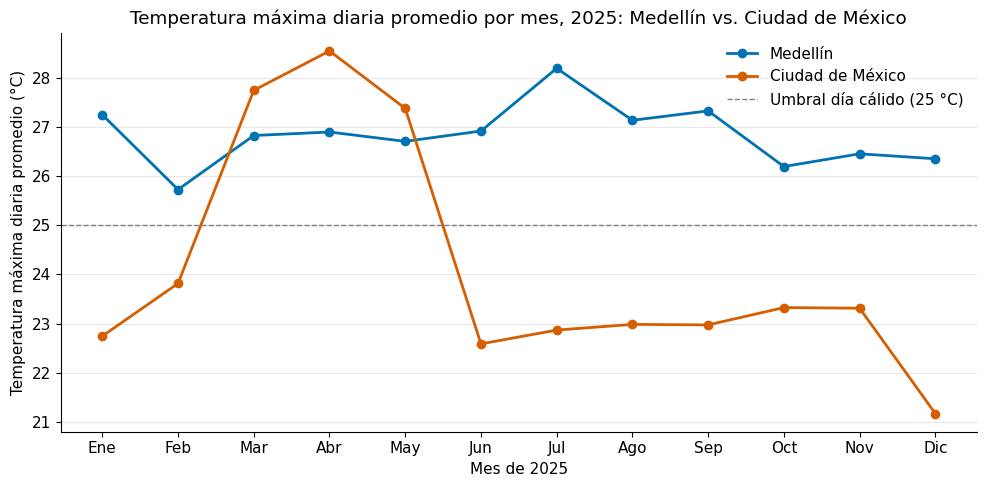

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
for i, nombre in enumerate(CIUDAD_NOMBRES):
    ax.plot(x, tmax_mensual[i], marker="o", lw=2, color=COLORES[nombre], label=nombre)
ax.axhline(UMBRAL_TEMP_C, color="gray", ls="--", lw=1, label=f"Umbral día cálido ({UMBRAL_TEMP_C:.0f} °C)")
ax.set_xticks(x, NOMBRES_MES)
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Temperatura máxima diaria promedio (°C)")
ax.set_title("Temperatura máxima diaria promedio por mes, 2025: Medellín vs. Ciudad de México")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Patrón observado:** Medellín se mantiene entre 25.7 °C (febrero) y 28.2 °C (julio), un rango de apenas 2.5 °C en todo el año. Ciudad de México va de 21.2 °C (diciembre) a 28.6 °C (abril), un rango de 7.4 °C. En marzo, abril y mayo, la curva de Ciudad de México queda por encima de la de Medellín (27.7 vs 26.8 °C en marzo, 28.6 vs 26.9 °C en abril, 27.4 vs 26.7 °C en mayo). El resto del año queda por debajo.

**Qué no permite concluir:** el gráfico usa promedios mensuales de la temperatura máxima, así que no muestra noches ni días extremos. Como es un solo año, no sirve para decir que ese patrón se repite cada año. No explica por qué ocurre.

### 5.2 Precipitación acumulada mensual (barras agrupadas)

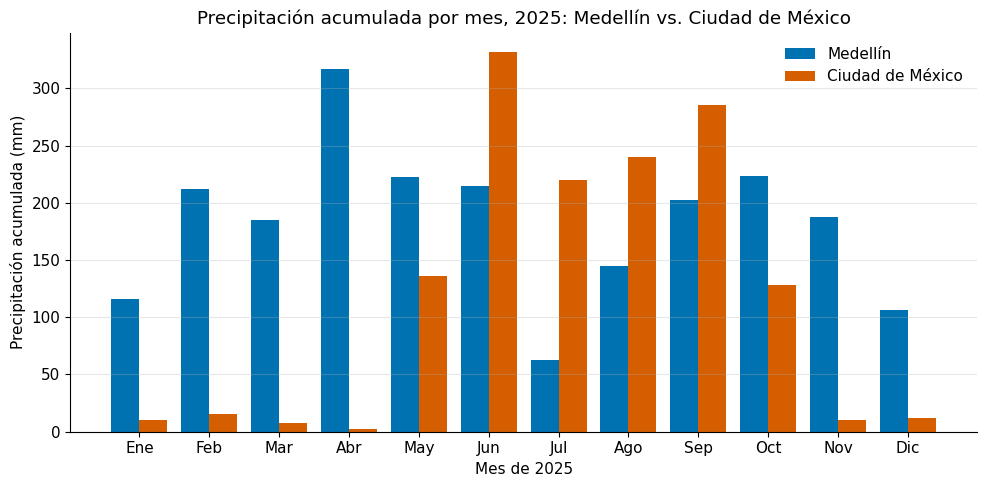

In [16]:
ancho = 0.4
fig, ax = plt.subplots(figsize=(10, 5))
for i, nombre in enumerate(CIUDAD_NOMBRES):
    ax.bar(x + (i - 0.5) * ancho, precip_mensual[i], width=ancho, color=COLORES[nombre], label=nombre)
ax.set_xticks(x, NOMBRES_MES)
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Precipitación acumulada (mm)")
ax.set_title("Precipitación acumulada por mes, 2025: Medellín vs. Ciudad de México")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Patrón observado:** Medellín recibe lluvia todos los meses, con máximos en abril (316.7 mm) y octubre (223.1 mm) y un mínimo en julio (62.9 mm). Ciudad de México tiene lluvia concentrada de mayo a octubre, con un máximo en junio (331.9 mm). De noviembre a abril acumula entre 2.0 y 15.9 mm por mes. El total anual es de 2 193.9 mm en Medellín y 1 400.4 mm en Ciudad de México. Entre junio y septiembre, Ciudad de México supera a Medellín.

**Qué no permite concluir:** son valores de un modelo de reanálisis con malla de varios kilómetros, no de un pluviómetro. Pueden diferir de lo que midieron las estaciones locales, y la lluvia de montaña puede estar mal representada. Un solo año tampoco permite decir cuál es el clima típico de cada ciudad.

### 5.3 Amplitud térmica diaria (histogramas)

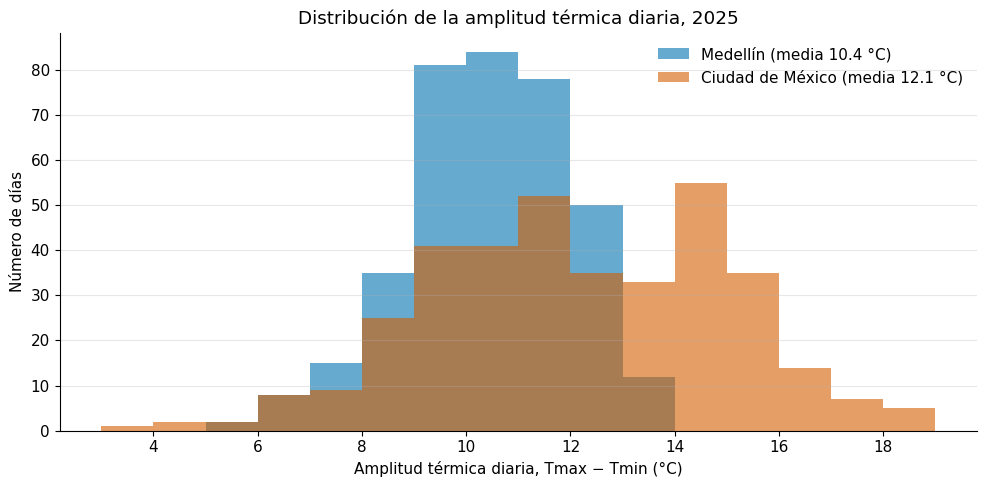

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.arange(3, 20, 1)
for i, nombre in enumerate(CIUDAD_NOMBRES):
    ax.hist(amplitud[i], bins=bins, alpha=0.6, color=COLORES[nombre],
            label=f"{nombre} (media {amplitud[i].mean():.1f} °C)")
ax.set_xlabel("Amplitud térmica diaria, Tmax − Tmin (°C)")
ax.set_ylabel("Número de días")
ax.set_title("Distribución de la amplitud térmica diaria, 2025")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Patrón observado:** la amplitud térmica de Medellín se concentra en un rango estrecho (de 5.0 a 13.6 °C, media de 10.4 °C). La de Ciudad de México tiene media mayor (12.1 °C) y se extiende mucho más (de 3.8 a 18.9 °C). La desviación estándar de Tmax también es mayor en Ciudad de México (3.1 °C) que en Medellín (1.4 °C).

**Qué no permite concluir:** el histograma no indica en qué época del año ocurren las amplitudes más grandes ni más pequeñas. Tampoco dice si esa diferencia se debe a la altitud, la humedad o la nubosidad, porque ninguna de esas variables está en el análisis.

## 6. Interpretación de resultados

**Respuesta a la pregunta guía.** En 2025, Medellín tuvo una temperatura máxima más alta en promedio (26.8 °C contra 24.1 °C), mucho más estable y con bastante más lluvia. Ciudad de México varió más en temperatura y concentró la lluvia en pocos meses.

### Hallazgo 1 — Similitud: las dos ciudades tienen días más frescos cuando llueve, y ambas tienen una temporada lluviosa marcada

- En las dos ciudades la Tmax media es menor en días lluviosos que en días no lluviosos: 26.47 vs 27.86 °C en Medellín y 22.65 vs 25.16 °C en Ciudad de México.
- Las dos ciudades tienen un mes con más de 300 mm: abril en Medellín (316.7 mm) y junio en Ciudad de México (331.9 mm).

Esto es una asociación observada. No concluyo que la lluvia cause el descenso de temperatura.

### Hallazgo 2 — Diferencia: Medellín tiene lluvia y calor casi todo el año; Ciudad de México tiene estaciones muy marcadas

- Medellín tuvo **267 días lluviosos** y Ciudad de México **151**. Medellín acumuló 2 193.9 mm y Ciudad de México 1 400.4 mm.
- Con el mismo umbral de 25 °C, Medellín tuvo **332 días cálidos** y Ciudad de México **119**.
- En Ciudad de México, noviembre a abril sumaron solo 58.0 mm, frente a 1 342.4 mm de mayo a octubre. En Medellín, el mes más seco (julio) igual tuvo 62.9 mm.
- La Tmax mensual de Medellín varió 2.5 °C durante el año y la de Ciudad de México 7.4 °C.

### Hallazgo 3 — Matiz: Ciudad de México no siempre es más fresca

En marzo, abril y mayo la Tmax media mensual de Ciudad de México (27.7, 28.6 y 27.4 °C) superó a la de Medellín (26.8, 26.9 y 26.7 °C). En 82 de los 365 días, Ciudad de México tuvo una Tmax más alta que Medellín. Esto matiza la idea de que Ciudad de México es siempre más fresca.

### Qué expectativas se cumplieron

1. **Cumplida:** Medellín tuvo una temperatura máxima mucho más estable (desviación estándar 1.4 °C contra 3.1 °C).
2. **Cumplida:** Ciudad de México concentró la lluvia entre mayo y octubre. Medellín tuvo lluvia todos los meses, aunque con dos picos.
3. **Cumplida:** Ciudad de México acumuló menos precipitación anual (1 400.4 mm contra 2 193.9 mm).

### Efecto del periodo común y de los datos faltantes

- Las dos tablas cubren exactamente los mismos 365 días de 2025, con frecuencia diaria. Por eso las comparaciones mes a mes y día a día son directas.
- No hubo valores faltantes, así que las 365 observaciones se usaron completas. Si hubiera habido faltantes, habría que haber comparado solo los días válidos en ambas ciudades, y las sumas de precipitación habrían quedado subestimadas en la ciudad con huecos.
- Con un solo año no se puede saber si 2025 fue típico. Los patrones podrían cambiar en un año con fenómeno de El Niño o La Niña.

### Limitaciones

- **Reanálisis, no estación:** los datos son de un modelo con malla de varios kilómetros. Medellín está en un valle rodeado de montañas y Ciudad de México está en una cuenca. Una celda promedia zonas con altitudes distintas. Los valores pueden diferir de los de SIATA, IDEAM o el Servicio Meteorológico Nacional de México.
- **Umbrales elegidos por mí:** 25 °C y 1 mm son decisiones propias. Con otros umbrales cambian los conteos, aunque la comparación entre ciudades se hace con el mismo criterio.
- **Altitud distinta:** Medellín está a unos 1 490 m y Ciudad de México a unos 2 230 m, según los metadatos de la malla. Esto hace que la comparación de temperaturas no sea entre ciudades al mismo nivel.
- **Sin causalidad:** el análisis describe diferencias y asociaciones. No identifica las causas de ellas.